# RMC AI Labs — Lab 05: Monitoramento com histórico real anonimizado

**Objetivo:** PSI e MAE em janelas de 7 dias, segmentação por VM e investigação de erro persistente. Este notebook **não** inventa anomalias e utiliza os CSVs do Lab 02. **Execute para obter os números reais.**

## 1. Verificar o ambiente
Este notebook executa o mesmo arquivo `executar_lab05_real.py` para evitar lógica divergente entre notebook e script. O kernel deve ser `mlops-mini`.

In [1]:
import sys, pandas as pd, numpy as np
from pathlib import Path
print('Python:',sys.version.split()[0])
print('Pandas:',pd.__version__)
print('Notebook:',Path.cwd())

Python: 3.12.15
Pandas: 3.0.6
Notebook: /home/francisco/PythonProjects/LAB_POSTS/mlops/rmc-mlops-mini/posts/monitoramento_janelas_reais


## 2. Executar o monitoramento
O script lê `../monitoramento_dados/dados/cpu.csv` e `mem.csv`, ajusta uma regressão linear apenas no treino, calcula PSI/MAE nas janelas reais e grava as evidências.

In [2]:
import subprocess
from pathlib import Path
script = Path('executar_lab05_real.py')
if not script.exists():
    script = Path('posts/monitoramento_janelas_reais/executar_lab05_real.py')
assert script.exists(), 'Abra o notebook a partir da pasta do Lab 05 ou da raiz do clone'
subprocess.run([sys.executable, str(script)], check=True)

Fonte declarada: RMC_Recursos_vialactea.xlsx
{
  "fonte": "RMC_Recursos_vialactea.xlsx",
  "tipo_dados": "medições históricas reais, identificadores fictícios",
  "periodo_treino": "antes de 2026-05-01",
  "periodo_referencia": "2026-05-01 a 2026-05-14",
  "periodo_avaliacao": "a partir de 2026-05-15",
  "n_treino": 11384,
  "n_referencia": 3256,
  "n_avaliacao": 6318,
  "n_vms_avaliadas": 234,
  "data_final": "2026-06-10",
  "mae_ref_pp": 0.9238,
  "limiar_mae_vm_pp_95p": 3.5301,
  "janela_dias": 7,
  "persistencia_dias": 3,
  "vms_investigar_data_final": 22,
  "PSI_CPU_ultima_janela": 0.0517,
  "PSI_MEM_ultima_janela": 0.0146,
  "MAE7_GLOBAL_ultima_janela": 1.1564,
  "advertencia": "PSI nao prova concept drift. MAE maior sozinho nao prova mudanca de P(Y|X). Limiares exploratorios."
}
Evidências: /home/francisco/PythonProjects/LAB_POSTS/mlops/rmc-mlops-mini/posts/monitoramento_janelas_reais/evidencias_reais


CompletedProcess(args=['/home/francisco/miniconda3/envs/mlops-mini/bin/python', 'executar_lab05_real.py'], returncode=0)

## 3. Conferir números e figuras
Os números exibidos abaixo são produzidos pela execução local e não representam resultados predefinidos.

{
  "fonte": "RMC_Recursos_vialactea.xlsx",
  "tipo_dados": "medições históricas reais, identificadores fictícios",
  "periodo_treino": "antes de 2026-05-01",
  "periodo_referencia": "2026-05-01 a 2026-05-14",
  "periodo_avaliacao": "a partir de 2026-05-15",
  "n_treino": 11384,
  "n_referencia": 3256,
  "n_avaliacao": 6318,
  "n_vms_avaliadas": 234,
  "data_final": "2026-06-10",
  "mae_ref_pp": 0.9238,
  "limiar_mae_vm_pp_95p": 3.5301,
  "janela_dias": 7,
  "persistencia_dias": 3,
  "vms_investigar_data_final": 22,
  "PSI_CPU_ultima_janela": 0.0517,
  "PSI_MEM_ultima_janela": 0.0146,
  "MAE7_GLOBAL_ultima_janela": 1.1564,
  "advertencia": "PSI nao prova concept drift. MAE maior sozinho nao prova mudanca de P(Y|X). Limiares exploratorios."
}


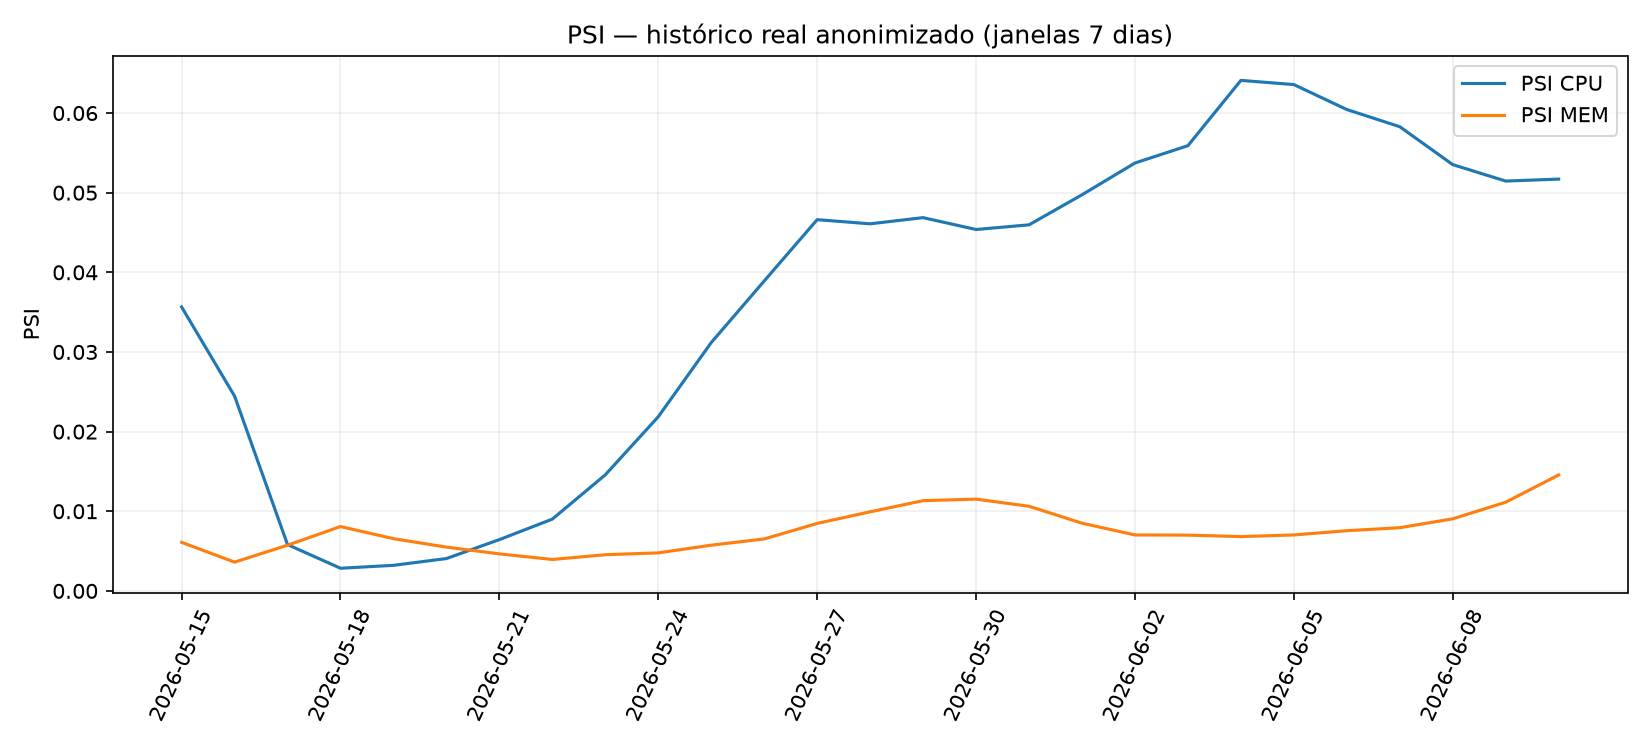

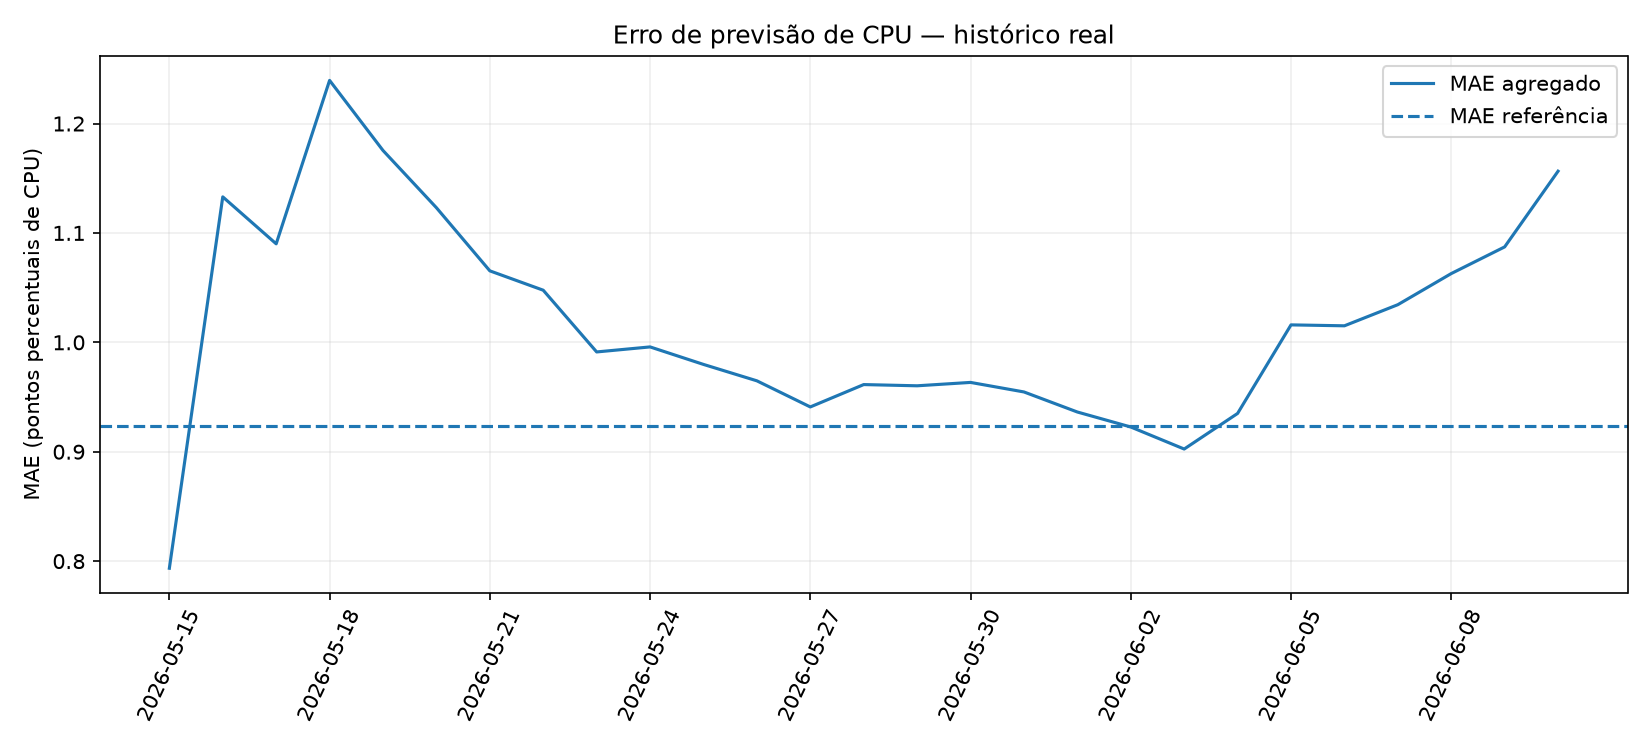

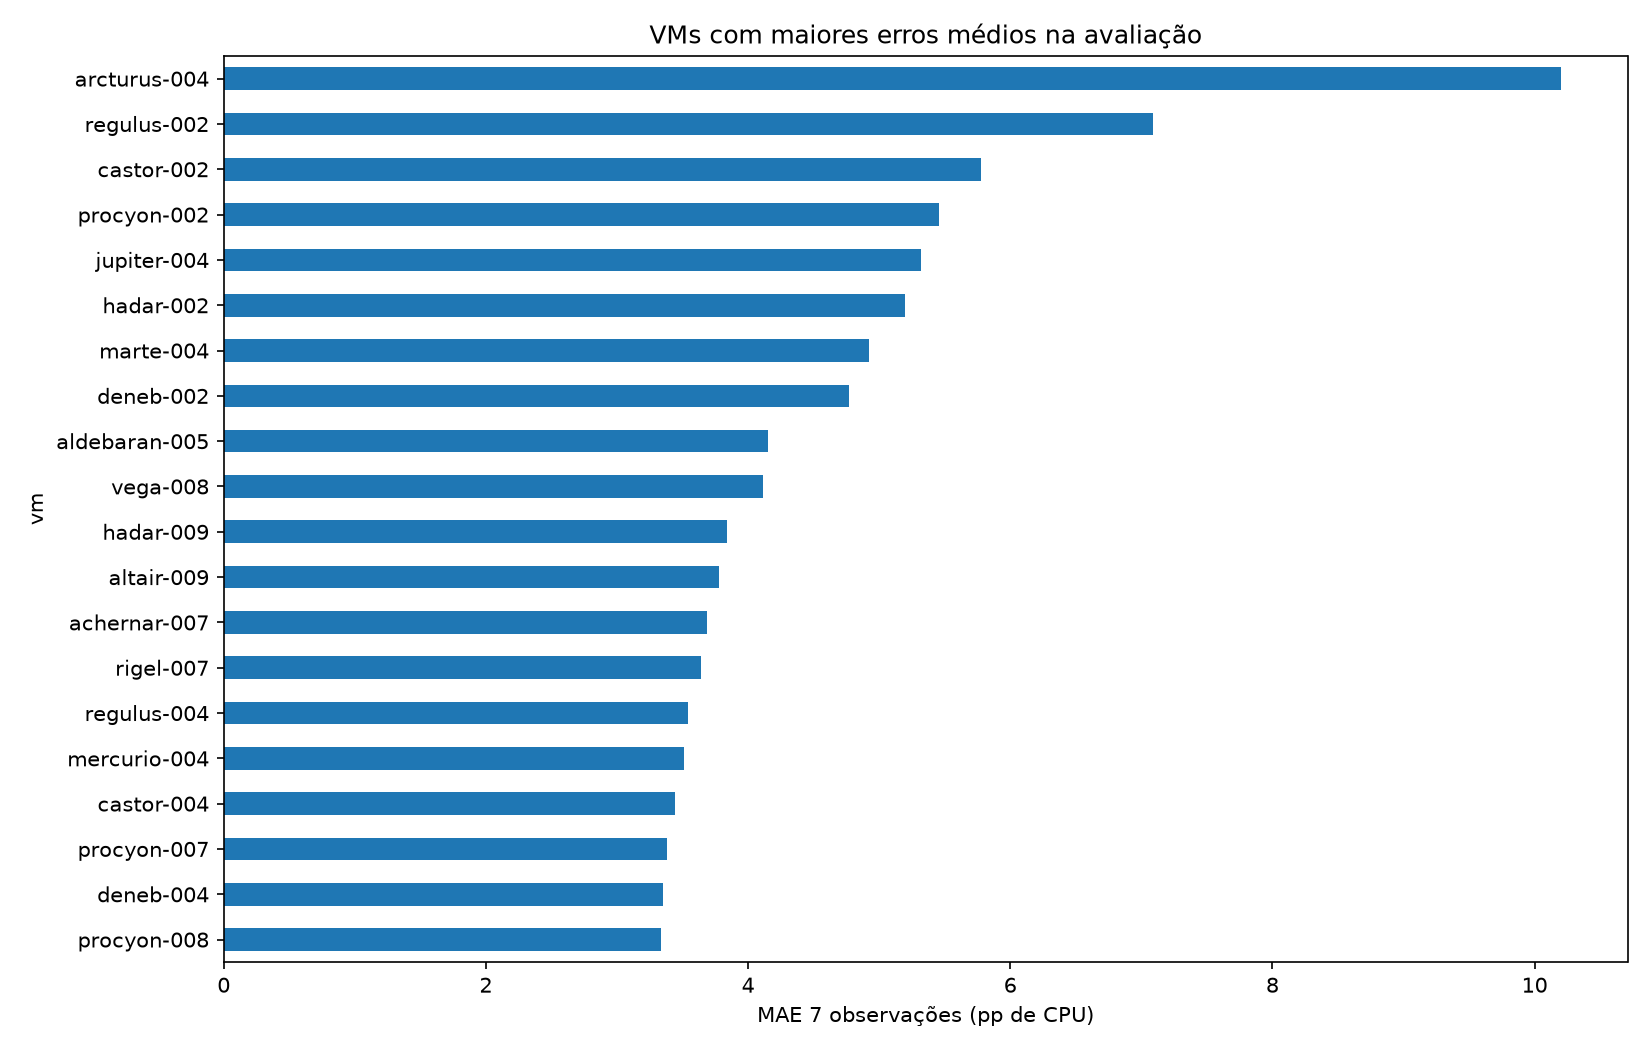

In [3]:
import json
from IPython.display import display, Image
evidencias=script.parent/'evidencias_reais'
resultado=json.loads((evidencias/'resultados.json').read_text())
print(json.dumps(resultado,ensure_ascii=False,indent=2))
for arquivo in ['psi_janelas_reais.png','mae_janelas_reais.png','ranking_mae_vms.png']:
    display(Image(filename=str(evidencias/arquivo)))

## 4. Interpretar com responsabilidade
- PSI acima do esperado significa mudança de distribuição, não erro garantido.
- MAE elevado significa erro maior, mas não comprova sozinho concept drift.
- Alerta persistente sugere investigar dados, contexto e sazonalidade antes de decidir por retreinamento.
- O laboratório observa somente VMs com séries suficientes nas janelas.